# Lecture 23, Spatial downscaling

> From a coarse grid to the detail a catchment needs: interpolation, BCSD, constructed analogues and stochastic analogues

Lecture 18 corrected the *statistics* of a model (quantile mapping), and Lectures 19&ndash;22 built the *relationship* between large-scale predictors and a local variable. This lecture deals with the **space** dimension. A GCM or reanalysis rainfall field lives on cells 100&ndash;250 km wide. A catchment in the Western Ghats or the Himalaya has rainfall that changes over 10 km, because the terrain does. How do we get from the one to the other?

By the end of this lecture you should be able to:

- explain why spatial downscaling is needed, and derive **bilinear interpolation** (linear in $x$, then in $y$, equal to an area-weighted mean of four cells), showing that its weights sum to one and that it adds smoothness but **no information**;
- say why interpolation alone fails, and why it is combined with **bias correction**;
- carry out **BCSD** step by step on a $2\times2 \to 4\times4$ grid by hand and on a $4\times4 \to 16\times16$ grid in numpy, and explain **multiplicative versus additive** scaling;
- **derive** the constructed-analogue weights as a least-squares problem, show why they need **regularisation** (ridge) and a restriction to the best $N$ days (**BCCA**);
- describe **BCSA**, a *stochastic* method that keeps realistic variability where constructed analogues smooth it;
- compare the methods with a table and with metrics on a **held-out period**: pattern correlation, bias, variance ratio and preserved spatial detail.

All data in this lecture are **synthetic** (an invented orographic rainfall field), so that the "truth" at fine resolution is known. A companion workbook, `data/downscaling/lec23/lec23_worked_examples.xlsx`, has the three small worked examples with live formulas; the code cells print the same numbers.

In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas matplotlib scipy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

BASE = "data/downscaling/lec23/"
RAW = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/downscaling/lec23/"

def load(name):
    """Read a header-less CSV matrix: from the repository folder, or from GitHub (e.g. on Colab)."""
    try:
        return pd.read_csv(BASE + name, header=None).to_numpy(float)
    except FileNotFoundError:
        return pd.read_csv(RAW + name, header=None).to_numpy(float)

NF, NC, F = 16, 4, 4          # fine grid 16 x 16, coarse grid 4 x 4, F = 4 fine cells per coarse cell (per axis)

def block_mean(a):
    """Average each F x F block of a fine field: (..., 16, 16) -> (..., 4, 4)."""
    return a.reshape(*a.shape[:-2], NC, F, NC, F).mean(axis=(-3, -1))

elev     = load("terrain_elevation_km_16x16.csv")                    # synthetic terrain, km
fine_tr  = load("fine_obs_train.csv").reshape(-1, NF, NF)            # 240 "days" of fine-resolution observations
fine_te  = load("fine_obs_test.csv").reshape(-1, NF, NF)             # 60 held-out days (the truth we try to recover)
gcm_tr   = load("gcm_coarse_train.csv").reshape(-1, NC, NC)          # the biased coarse "GCM", same two periods
gcm_te   = load("gcm_coarse_test.csv").reshape(-1, NC, NC)
obs_c_tr = block_mean(fine_tr)                                       # coarse-aggregated observations (training)
obs_c_te = block_mean(fine_te)
print(f"training days {len(fine_tr)}, held-out days {len(fine_te)}; fine grid {NF}x{NF}, coarse grid {NC}x{NC}")

training days 240, held-out days 60; fine grid 16x16, coarse grid 4x4


# 1) The task, and a synthetic world to try it on

A GCM (Lecture 13) returns one number per coarse cell and day. Take a cell of 1&deg; (about 110 km). Inside it a hydrologist sees a windward slope that receives several times the rain of the lee side, a valley with its own temperature, a catchment of 500 km$^2$. **Spatial downscaling** converts the coarse field $\mathbf{y}$ (with $q$ cells) into a fine field $\mathbf{x}$ (with $p \gg q$ cells), or into the value for one catchment, with the spatial detail that the coarse model cannot resolve. In India the fine target is typically the **IMD gridded rainfall** (0.25&deg;) or a station network, and the coarse input a CMIP6 field (for example the daily NEX-GDDP-CMIP6 product, itself already bias corrected and downscaled at 0.25&deg;).

Two different jobs are hidden in this phrase:

1. **Putting the right fine-scale *climatology* back**: where it is on average wet and dry (terrain, coast, rain shadow). This is *static* detail, learnt from fine observations.
2. **Putting the right fine-scale *weather* back**: how a particular day's rain is spread in space. This is *dynamic* detail and it can only be inferred from the coarse field and from what the past tells us about how coarse and fine fields go together.

A third issue, that the model's coarse values are **biased**, is handled by the quantile mapping of Lecture 18.

**The synthetic world.** To test the methods we need a known truth, so we invent one. The fine grid is $16\times16$ cells of 0.25&deg; (a 4&deg; &times; 4&deg; region); the coarse grid is $4\times4$ cells of 1&deg;. The terrain has a north&ndash;south ridge about a third of the way across (a windward slope) and one smaller hill. Daily rainfall is a *terrain factor*, larger on the ridge on days of strong onshore flow, times a smooth random weather pattern and a bit of local noise. The "GCM" sees only the $4\times4$ block averages, is **too wet in the west and too dry in the east**, has too heavy a tail, and makes timing errors. Two independent periods are generated: 240 days to *train* every method and 60 days *held out* for testing. These are not real data. (To use real data, replace the fine fields by IMD gridded rainfall and the coarse model by a CMIP6 or NEX-GDDP-CMIP6 field regridded to a coarser grid; everything below then runs unchanged, apart from the day-by-day scores explained in Section 6.)

mean fine rainfall 5.69 mm/day; ridge cells average 12.4, cells east of the ridge 3.8 mm/day


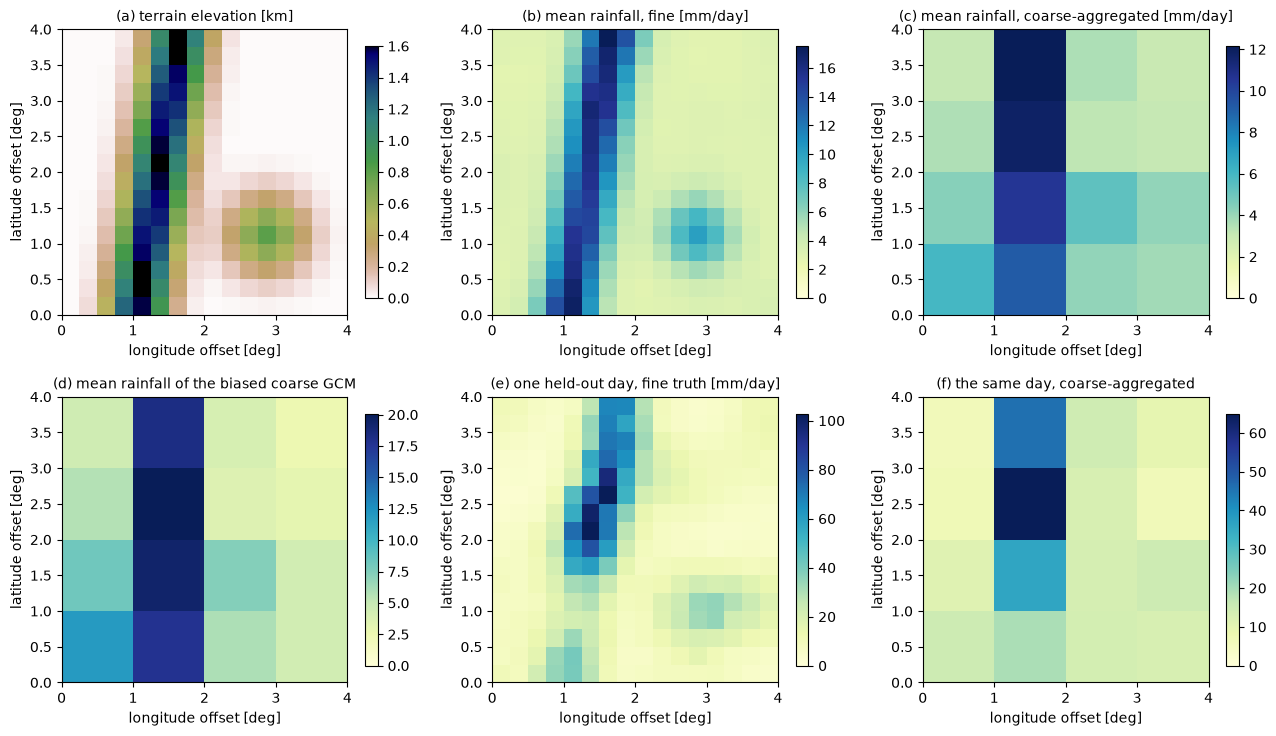

In [3]:
ext = [0, 4, 0, 4]   # degrees, for the axes of the maps (synthetic region)
ridge_day = int(np.argmax(fine_te.reshape(len(fine_te), -1).max(1)))   # a wet test day with a strong ridge effect

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
panels = [
    (elev, "(a) terrain elevation [km]", "terrain", None),
    (fine_tr.mean(0), "(b) mean rainfall, fine [mm/day]", "YlGnBu", None),
    (obs_c_tr.mean(0), "(c) mean rainfall, coarse-aggregated [mm/day]", "YlGnBu", None),
    (gcm_tr.mean(0), "(d) mean rainfall of the biased coarse GCM", "YlGnBu", None),
    (fine_te[ridge_day], f"(e) one held-out day, fine truth [mm/day]", "YlGnBu", None),
    (obs_c_te[ridge_day], "(f) the same day, coarse-aggregated", "YlGnBu", None),
]
for ax, (fld, title, cmap, _) in zip(axes.ravel(), panels):
    im = ax.imshow(fld, origin="lower", extent=ext, cmap="gist_earth_r" if cmap == "terrain" else cmap,
                   vmin=0, vmax=None, interpolation="nearest")
    ax.set_title(title, fontsize=10); ax.set_xlabel("longitude offset [deg]"); ax.set_ylabel("latitude offset [deg]")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
print(f"mean fine rainfall {fine_tr.mean():.2f} mm/day; ridge cells average {fine_tr.mean(0)[:, 4:7].mean():.1f}, "
      f"cells east of the ridge {fine_tr.mean(0)[:, 9:].mean():.1f} mm/day")

Panel (b) is what a catchment hydrologist needs: a ridge of 10 mm/day or more against 3&ndash;4 mm/day elsewhere. Panel (c) shows what is left after averaging to the coarse grid. The ridge, only 2&ndash;3 fine cells (0.5&ndash;0.7&deg;) wide, has all but disappeared inside one coarse column, and panel (d) adds the model's bias on top. **No interpolation of panel (c) can bring the ridge back**; Section 2 makes this precise.

# 2) Interpolation: the baseline

The simplest spatial downscaling is to **interpolate** the coarse field to the fine grid.

**Nearest neighbour** gives each fine cell the value of the nearest coarse cell. The result is a blocky copy of the coarse field. No new values are created, and every fine cell inside a coarse cell is identical.

**Bilinear interpolation** is smoother. Put the four coarse values around a fine point on the corners of a rectangle: $z_{00}$ at $(x_i, y_j)$, $z_{10}$ at $(x_{i+1}, y_j)$, $z_{01}$ at $(x_i, y_{j+1})$ and $z_{11}$ at $(x_{i+1}, y_{j+1})$. Let the point be at $(x, y)$ and define the fractions of the way across the cell

$$t_x = \frac{x - x_i}{x_{i+1} - x_i}, \qquad t_y = \frac{y - y_j}{y_{j+1} - y_j}, \qquad 0 \le t_x, t_y \le 1 .$$

*Step 1, linear in $x$* along the lower and the upper edge of the rectangle:

$$z_{\text{low}} = (1 - t_x)\, z_{00} + t_x\, z_{10}, \qquad z_{\text{up}} = (1 - t_x)\, z_{01} + t_x\, z_{11}.$$

*Step 2, linear in $y$* between those two edge values:

$$z(x,y) = (1 - t_y)\, z_{\text{low}} + t_y\, z_{\text{up}} .$$

Substituting step 1 into step 2 and collecting the four corner values gives

$$\boxed{\; z(x,y) = w_{00} z_{00} + w_{10} z_{10} + w_{01} z_{01} + w_{11} z_{11}, \quad
w_{00} = (1-t_x)(1-t_y),\; w_{10} = t_x(1-t_y),\; w_{01} = (1-t_x)\,t_y,\; w_{11} = t_x t_y \;}$$

Each weight is the **area of the rectangle opposite the corner**, as a fraction of the whole cell (the point splits the cell into four rectangles; the closer a corner, the larger the rectangle on the other side). It is therefore an *area-weighted average* of the four neighbours. The weights add to one:

$$w_{00}+w_{10}+w_{01}+w_{11} = (1-t_y)\big[(1-t_x)+t_x\big] + t_y\big[(1-t_x)+t_x\big] = (1-t_y) + t_y = 1 .$$

All weights are also $\ge 0$, so the interpolated value is a **convex combination** of the four corners and lies between the smallest and the largest of them. Two consequences matter for downscaling:

- Bilinear interpolation can **never create a new extreme**: the maximum of the fine field is no larger than the maximum of the coarse field. A flood-producing peak inside a coarse cell cannot appear.
- It adds **no information**. The $p$ fine values are fixed linear functions of the $q$ coarse values, so the fine field still has only $q$ degrees of freedom. What is added is *smoothness*, not detail.

*Where are the coarse "nodes"?* A coarse cell of $F$ fine cells (here $F=4$) is represented by its centre. In units of fine cells, the centre of coarse cell $k$ is at $Fk + (F-1)/2$ ($1.5, 5.5, 9.5, 13.5$ for $F=4$). Fine cells outside the outermost centres take the nearest coarse value (no extrapolation).

First the hand-checkable example of the workbook (sheet `Bilinear`): a $4\times4$ coarse grid and six target points.

In [4]:
def bilinear_at(z, x, y):
    """Four-corner weights and corner values for the point (x, y); z[j, i] is the node at (x = i, y = j)."""
    i = min(int(np.floor(x)), z.shape[1] - 2); j = min(int(np.floor(y)), z.shape[0] - 2)
    tx, ty = x - i, y - j
    w = np.array([(1 - tx) * (1 - ty), tx * (1 - ty), (1 - tx) * ty, tx * ty])        # w00, w10, w01, w11
    corners = np.array([z[j, i], z[j, i + 1], z[j + 1, i], z[j + 1, i + 1]])
    return tx, ty, w, corners

Z = load("bilinear_coarse_4x4.csv")            # synthetic coarse values (mm/day)
pts = load("bilinear_points_xy.csv")           # six target points (x, y), in coarse-cell units
rows = []
for x, y in pts:
    tx, ty, w, c = bilinear_at(Z, x, y)
    two_step = (1 - ty) * ((1 - tx) * c[0] + tx * c[1]) + ty * ((1 - tx) * c[2] + tx * c[3])
    nearest = Z[int(np.floor(y + 0.5)), int(np.floor(x + 0.5))]
    rows.append([x, y, *w, w.sum(), two_step, w @ c, nearest])
tab = pd.DataFrame(rows, columns=["x", "y", "w00", "w10", "w01", "w11", "sum w", "two-step", "four-weight", "nearest"])
print(tab.round(4).to_string(index=False))
print(f"\ncoarse values range {Z.min():.0f} to {Z.max():.0f}; interpolated values range {tab['four-weight'].min():.2f} to {tab['four-weight'].max():.2f}")

   x    y    w00    w10    w01    w11  sum w  two-step  four-weight  nearest
0.50 0.50 0.2500 0.2500 0.2500 0.2500    1.0   20.0000      20.0000     30.0
1.25 1.75 0.1875 0.0625 0.5625 0.1875    1.0   21.4375      21.4375     22.0
1.00 1.00 1.0000 0.0000 0.0000 0.0000    1.0   30.0000      30.0000     30.0
2.40 0.60 0.2400 0.1600 0.3600 0.2400    1.0   11.2800      11.2800     16.0
0.20 2.80 0.1600 0.0400 0.6400 0.1600    1.0   10.0000      10.0000      8.0
2.90 2.90 0.0100 0.0900 0.0900 0.8100    1.0    5.6200       5.6200      5.0

coarse values range 5 to 30; interpolated values range 5.62 to 30.00


The two columns "two-step" and "four-weight" agree to rounding error, the weights add to 1, and the interpolated values stay inside the range of the coarse values: exactly what the derivation says. (The same numbers appear on the `Bilinear` sheet, computed there with `INDEX` and `SUMPRODUCT`.)

Now the test of what interpolation can do for the synthetic world. To isolate the effect of interpolation we give it a **perfect coarse field**: the exact $4\times4$ block averages of the true held-out day.

maximum: truth 102.9, bilinear 56.4 mm/day  (coarse maximum 65.0)
average spatial std inside a coarse cell: truth 9.73, bilinear 3.86, nearest 0.00 mm/day
RMSE against the truth: bilinear 12.24, nearest 12.07 mm/day


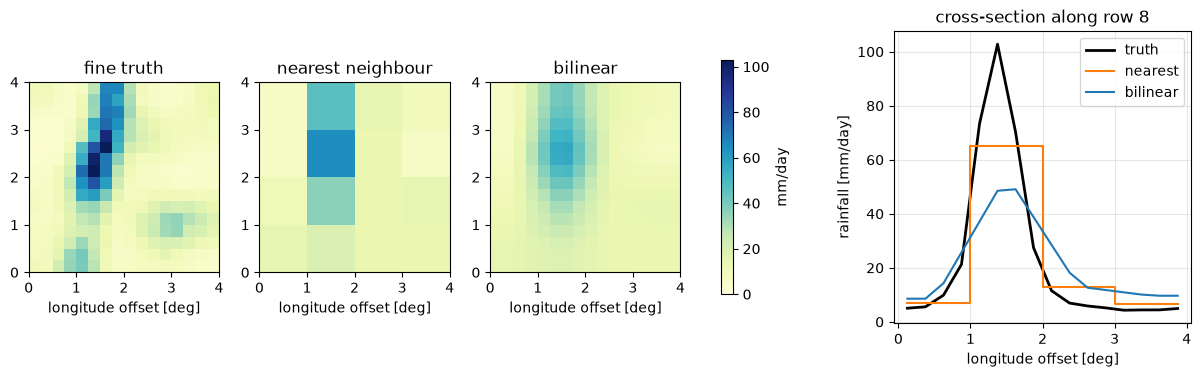

In [5]:
def axis_weights(nf, nc):
    """For each fine index, the lower coarse node and the fraction t of the way to the next one (cell-centre geometry)."""
    f = nf // nc
    pos = np.clip((np.arange(nf) - (f - 1) / 2) / f, 0, nc - 1)
    i0 = np.minimum(np.floor(pos).astype(int), nc - 2)
    return i0, pos - i0

def bilinear_grid(c, nf=NF):
    """Bilinear interpolation of coarse fields (..., nc, nc) to (..., nf, nf): along x first, then along y."""
    i0, t = axis_weights(nf, c.shape[-1])
    a = c[..., :, i0] * (1 - t) + c[..., :, i0 + 1] * t
    return a[..., i0, :] * (1 - t)[:, None] + a[..., i0 + 1, :] * t[:, None]

def nearest_grid(c, nf=NF):
    return np.kron(c, np.ones((nf // c.shape[-1], nf // c.shape[-1]))) if c.ndim == 2 else np.array([nearest_grid(a, nf) for a in c])

truth = fine_te[ridge_day]
nn, bl = nearest_grid(obs_c_te[ridge_day]), bilinear_grid(obs_c_te[ridge_day])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
for ax, fld, title in zip(axes[:3], [truth, nn, bl], ["fine truth", "nearest neighbour", "bilinear"]):
    im = ax.imshow(fld, origin="lower", extent=ext, cmap="YlGnBu", vmin=0, vmax=truth.max()); ax.set_title(title)
    ax.set_xlabel("longitude offset [deg]")
fig.colorbar(im, ax=axes[:3], shrink=0.8, label="mm/day")
row = 8
xs = (np.arange(NF) + 0.5) * 0.25
axes[3].plot(xs, truth[row], "k", lw=2, label="truth")
axes[3].step(xs, nn[row], where="mid", color="tab:orange", label="nearest")
axes[3].plot(xs, bl[row], color="tab:blue", label="bilinear")
axes[3].set_xlabel("longitude offset [deg]"); axes[3].set_ylabel("rainfall [mm/day]")
axes[3].set_title(f"cross-section along row {row}"); axes[3].legend(); axes[3].grid(alpha=0.3)

within = lambda a: a.reshape(NC, F, NC, F).transpose(0, 2, 1, 3).reshape(NC, NC, F * F).std(-1).mean()
print(f"maximum: truth {truth.max():.1f}, bilinear {bl.max():.1f} mm/day  (coarse maximum {obs_c_te[ridge_day].max():.1f})")
print(f"average spatial std inside a coarse cell: truth {within(truth):.2f}, bilinear {within(bl):.2f}, nearest {within(nn):.2f} mm/day")
print(f"RMSE against the truth: bilinear {np.sqrt(((bl - truth)**2).mean()):.2f}, nearest {np.sqrt(((nn - truth)**2).mean()):.2f} mm/day")

Bilinear interpolation smooths the blocks, but the peak of the ridge is **roughly halved** (about 56 against 103 mm/day on this day): the interpolated maximum is no larger than the largest coarse value, and the within-cell variability (the spatial standard deviation inside a coarse cell) is a fraction of the true one. The structure inside the coarse cells is simply not in the input.

**Limits of pure interpolation**, then:

1. It cannot add fine-scale *pattern* (ridge, rain shadow, coastal gradient), because that information is not in the coarse field.
2. It **smooths extremes** (convex combination), which matters for floods.
3. It inherits the **bias** of the coarse field. If the GCM is wet in the west and dry in the east, so is the interpolated field.
4. It is deterministic, so the variance at a fine point is that of a smooth blend of coarse cells, not that of a real point.

The standard remedy has two parts. **Bias-correct** the coarse field first (Lecture 18), so that what we interpolate has the right statistics. Then add the missing fine-scale detail from **fine-resolution observations**, which carry the terrain: through the observed fine *climatology* (BCSD), or through the observed fine *fields of similar days* (analogues). The next three sections are three ways of doing the second step.

# 3) BCSD: bias correction and spatial disaggregation

BCSD (Wood et al., 2004) was the workhorse of hydrological climate-impact studies for a decade. Write $i = 1,\dots,q$ for coarse cells and $j = 1,\dots,p$ for fine cells; $y_{\text{obs},i}$ is the observation aggregated to coarse cell $i$, $y_{\text{gcm},i}$ the GCM value, $x_{\text{obs},j}$ the fine observation. It is applied **month by month** to monthly or daily values; we use one "season". The algorithm:

1. **Bias correction at coarse scale.** For every coarse cell, map the GCM value to the observed coarse-scale distribution by quantile mapping (Lecture 18):
$$\tilde{y}_i = F_{\text{obs},i}^{-1}\!\big(F_{\text{gcm},i}(y_{\text{gcm},i})\big).$$
The output $\tilde y_i$ lives in the *observed* climate at coarse scale. (For a changing climate Lecture 18's quantile *delta* mapping keeps the projected change.)
2. **Scaling factor.** Compare today's corrected value with the coarse observed climatology $\bar y_{\text{obs},i}$ (the long-term mean for that month):
$$R_i = \frac{\tilde y_i}{\bar y_{\text{obs},i}} \quad\text{(multiplicative, rainfall)},\qquad A_i = \tilde y_i - \bar y_{\text{obs},i}\quad\text{(additive, temperature)}.$$
3. **Spatial interpolation** of the *factor* (not of the rainfall) to the fine grid, bilinear as in Section 2: $R_j = \mathcal I[R_i]$.
4. **Rescale by the fine climatology** $\bar x_{\text{obs},j}$ (the long-term mean of the fine observations):
$$\hat x_j = R_j\, \bar x_{\text{obs},j}\quad\text{or}\quad \hat x_j = \bar x_{\text{obs},j} + A_j .$$

The idea in words: *the coarse model tells us how much wetter or drier than usual the day (or month) is over each area; the fine observed climatology tells us what "usual" looks like in detail.* The smooth interpolated factor is harmless because it is only a modest correction around 1; the sharp terrain pattern comes from $\bar x_{\text{obs},j}$, which is not interpolated at all.

**Multiplicative or additive?** For **rainfall** use the ratio. (i) It keeps the result non-negative ($R \ge 0$, $\bar x \ge 0$), while adding a "$-2$ mm" anomaly to a dry cell could give negative rain. (ii) It assumes that wetter-than-normal means *proportionally* wetter everywhere: a day 20 % above normal adds 0.6 mm/day where the mean is 3 and 3 mm/day on a 15 mm/day ridge, which is physically sensible; an additive anomaly would add the same millimetres on both. (iii) If the model is exactly normal ($\tilde y_i = \bar y_{\text{obs},i}$) then $R=1$ and the output is the observed fine climatology, as it must be. For **temperature** use the difference: a ratio is not meaningful on a scale whose zero is arbitrary (below, the same ratio in &deg;C and in K gives different answers, and a ratio with a clima­tology near $0$ &deg;C explodes), and warming in &deg;C is roughly the same over a region.

**What BCSD assumes.** (a) The *spatial pattern of the climatology* is stationary: the ridge stays where it is and keeps its relative size. (b) Anomalies of the coarse field are smooth in space, so interpolating them loses little. (c) The pattern of the day inside a coarse cell is the climatological one, never the pattern of a particular storm. It consequently cannot make the ridge relatively wetter on days of strong onshore flow. A useful check: if the fine climatology averaged over coarse cell $i$ equals $\bar y_{\text{obs},i}$ (true when the coarse observations are aggregates of the fine ones) and $R$ is nearly constant inside the cell, then the cell mean of $\hat x$ is $R_i \bar y_{\text{obs},i} = \tilde y_i$. BCSD therefore approximately **conserves the coarse value**, though not exactly.

First by hand: the workbook sheet `BCSD_2x2` (a $2\times2$ coarse grid, a $4\times4$ fine grid; the quantile-mapping step is assumed done).

In [6]:
Ybar = load("bcsd_coarse_clim_2x2.csv")     # coarse observed climatology (mm/day)
y_bc = load("bcsd_gcm_bc_today_2x2.csv")    # bias-corrected coarse GCM value today (mm/day)
xbar = load("bcsd_fine_clim_4x4.csv")       # fine observed climatology (mm/day)

R = y_bc / Ybar                             # step 2: factor
Rf = bilinear_grid(R, nf=4)                 # step 3: interpolate the factor 2x2 -> 4x4
P = Rf * xbar                               # step 4: rescale by the fine climatology
show = lambda a, d=2: print(np.array2string(a, precision=d, suppress_small=True))
print("coarse climatology Ybar:"); show(Ybar)
print("BC coarse GCM today y:"); show(y_bc)
print("factor R = y / Ybar:"); show(R)
print("interpolated factor R_f (4x4):"); show(Rf, 3)
print("downscaled rainfall R_f * xbar (mm/day):"); show(P)
print("block means of the result:"); show(P.reshape(2, 2, 2, 2).mean(axis=(1, 3)))
print("block means of xbar (equal to Ybar, as required):"); show(xbar.reshape(2, 2, 2, 2).mean(axis=(1, 3)))
print("\nfor comparison, plain interpolation of y, with no climatology:"); show(bilinear_grid(y_bc, nf=4))

coarse climatology Ybar:
[[2. 4.]
 [6. 8.]]
BC coarse GCM today y:
[[ 3.  4.]
 [ 3. 12.]]
factor R = y / Ybar:
[[1.5 1. ]
 [0.5 1.5]]
interpolated factor R_f (4x4):
[[1.5   1.375 1.125 1.   ]
 [1.25  1.219 1.156 1.125]
 [0.75  0.906 1.219 1.375]
 [0.5   0.75  1.25  1.5  ]]
downscaled rainfall R_f * xbar (mm/day):
[[ 1.5   4.12  3.38  5.  ]
 [ 1.88  3.05  4.05  5.06]
 [ 3.    7.25  7.31 13.75]
 [ 2.5   5.25  8.75 13.5 ]]
block means of the result:
[[ 2.64  4.37]
 [ 4.5  10.83]]
block means of xbar (equal to Ybar, as required):
[[2. 4.]
 [6. 8.]]

for comparison, plain interpolation of y, with no climatology:
[[ 3.    3.25  3.75  4.  ]
 [ 3.    3.75  5.25  6.  ]
 [ 3.    4.75  8.25 10.  ]
 [ 3.    5.25  9.75 12.  ]]


Check one cell by hand. The coarse factors are $R = \begin{pmatrix}1.5 & 1\\ 0.5 & 1.5\end{pmatrix}$: the north-west cell is 50 % wetter than usual and the south-west cell 50 % drier. The interpolated factor varies smoothly between them, and multiplying by the fine climatology puts the within-cell pattern (the 3 mm/day versus 1 mm/day neighbours in the first row, for instance) back, which plain interpolation of $y$ cannot do. The block means of the result differ from the coarse values $y$ (they are $2.6,\,4.4,\,4.5,\,10.8$ against $3,\,4,\,3,\,12$): the conservation is only approximate here, as announced: the factor changes a lot across this tiny grid, so the assumption "R nearly constant inside the cell" is poor.

Now **additive** scaling for temperature, and the reason not to use a ratio there. Take a cold high-altitude area: the coarse winter climatology is $2$ &deg;C, today the corrected model gives $3$ &deg;C (one degree warmer), and the fine climatology at a valley point is $-3$ &deg;C.

In [7]:
Ybar_T, y_T, xbar_T = 2.0, 3.0, -3.0
print(f"additive:        {xbar_T + (y_T - Ybar_T):+.2f} degC   (1 K warmer than the fine climatology, as expected)")
print(f"multiplicative:  {xbar_T * (y_T / Ybar_T):+.2f} degC   (the point gets 1.5 K COLDER on a warmer day)")
k = 273.15
print(f"multiplicative in kelvin, converted back: {xbar_T + k:.2f} * {(y_T + k) / (Ybar_T + k):.4f} - 273.15 = "
      f"{(xbar_T + k) * (y_T + k) / (Ybar_T + k) - k:+.2f} degC   (a different answer: the ratio depends on the zero of the scale)")

additive:        -2.00 degC   (1 K warmer than the fine climatology, as expected)
multiplicative:  -4.50 degC   (the point gets 1.5 K COLDER on a warmer day)
multiplicative in kelvin, converted back: 270.15 * 1.0036 - 273.15 = -2.02 degC   (a different answer: the ratio depends on the zero of the scale)


Now the full BCSD on the $4\times4 \to 16\times16$ synthetic world. Step 1 needs a quantile mapping per coarse cell. We use the empirical version of Lecture 18: for each cell, the GCM value is placed on the *training-period* empirical distribution of the GCM and replaced by the value with the same probability in the *training-period* observed coarse distribution (values beyond the training range are clamped to its ends; Lecture 18 discusses better extrapolation).

In [8]:
def quantile_map(model_train, obs_train, model_new):
    """Cell-by-cell empirical quantile mapping. Arrays: (days, nc, nc)."""
    out = np.empty_like(model_new)
    for i in range(model_new.shape[1]):
        for j in range(model_new.shape[2]):
            ms, os_ = np.sort(model_train[:, i, j]), np.sort(obs_train[:, i, j])
            p = (np.arange(len(ms)) + 0.5) / len(ms)
            out[:, i, j] = np.interp(np.interp(model_new[:, i, j], ms, p), p, os_)
    return out

def bcsd(y_bc_coarse, obs_coarse_clim, fine_clim, mode="multiplicative"):
    """Steps 2-4 of BCSD for coarse fields (days, nc, nc), given the observed coarse and fine climatologies."""
    if mode == "multiplicative":
        return bilinear_grid(y_bc_coarse / obs_coarse_clim) * fine_clim
    return bilinear_grid(y_bc_coarse - obs_coarse_clim) + fine_clim

# step 1: bias-correct the held-out coarse GCM with the training period
bc_te = quantile_map(gcm_tr, obs_c_tr, gcm_te)
# steps 2-4
clim_c, clim_f = obs_c_tr.mean(0), fine_tr.mean(0)
x_bcsd = bcsd(bc_te, clim_c, clim_f)

pct = lambda a: 100 * (a.mean(0) / obs_c_te.mean(0) - 1)              # bias of the held-out coarse mean per cell, %
print(f"coarse mean bias per cell, % : raw GCM from {pct(gcm_te).min():+.0f} to {pct(gcm_te).max():+.0f};"
      f" after quantile mapping from {pct(bc_te).min():+.0f} to {pct(bc_te).max():+.0f}")
print(f"BCSD result: min {x_bcsd.min():.2f}, max {x_bcsd.max():.1f} mm/day; "
      f"block means of the result differ from the corrected coarse field by {np.abs(block_mean(x_bcsd) - bc_te).mean():.2f} mm/day on average")

coarse mean bias per cell, % : raw GCM from -17 to +105; after quantile mapping from -3 to +2
BCSD result: min 0.68, max 75.5 mm/day; block means of the result differ from the corrected coarse field by 0.56 mm/day on average


# 4) BCCA: bias correction and constructed analogues

BCSD gives every day the same fine-scale pattern, the climatology. But on a day of strong onshore flow the ridge is *relatively* wetter than on a day of weak flow, and the coarse field of that day carries a hint of it (the coarse cell over the ridge is wetter than its neighbours). Constructed analogues (Hidalgo et al., 2008; used with bias correction by Maurer et al., 2010) use **past days whose coarse field resembles today's** and borrow their fine-scale patterns.

**Setting.** We have a library of $H$ observed days, each with a coarse field $\mathbf y^{(h)} \in \mathbb R^{q}$ (the aggregate) and a fine field $\mathbf x^{(h)} \in \mathbb R^{p}$. Today's bias-corrected coarse field is $\mathbf y$; the fine field $\mathbf x$ is unknown.

1. **Choose the $N$ best analogues**: the $N$ days with the smallest distance $\text{RMSE}_h = \sqrt{\tfrac1q\sum_i (y_i - y^{(h)}_i)^2}$. Stack their coarse fields as the columns of $Y = [\mathbf y^{(h_1)}, \dots, \mathbf y^{(h_N)}]$ ($q \times N$) and their fine fields in $X = [\mathbf x^{(h_1)}, \dots, \mathbf x^{(h_N)}]$ ($p \times N$).
2. **Construct today's coarse field from the analogues**: find weights $\mathbf w \in \mathbb R^N$ minimising the squared misfit
$$S(\mathbf w) = \lVert \mathbf y - Y\mathbf w\rVert^2 = (\mathbf y - Y \mathbf w)^{\!\top}(\mathbf y - Y\mathbf w).$$
Setting the gradient to zero, $\nabla_{\mathbf w} S = -2\,Y^{\!\top}(\mathbf y - Y \mathbf w) = \mathbf 0$, gives the **normal equations** and, if $Y^{\!\top}Y$ is invertible, the least-squares weights
$$Y^{\!\top}Y\,\mathbf w = Y^{\!\top}\mathbf y \quad\Rightarrow\quad \mathbf w = (Y^{\!\top}Y)^{-1} Y^{\!\top}\mathbf y .$$
3. **Apply the same weights to the fine fields**: $\hat{\mathbf x} = X\,\mathbf w$.

*Why step 3 is sensible.* Block averaging is a linear operator, $\mathbf y^{(h)} = A\,\mathbf x^{(h)}$ with $A$ a $q\times p$ matrix of averaging weights. Then $A\hat{\mathbf x} = A X\mathbf w = Y\mathbf w \approx \mathbf y$. **The constructed fine field reproduces today's coarse field as well as the analogues can**, which is exactly the consistency we want, and the fine-scale pattern is a blend of patterns that really occurred, so it is physically plausible (ridge rain with the right shape). The weights are unconstrained, so they may be negative, may not sum to one, and $X\mathbf w$ may be slightly negative; in practice negative values are set to zero.

**Why regularisation is needed.** $Y^{\!\top}Y$ is $N\times N$ but has rank at most $\min(q,N)$.

- If $N > q$ (more analogue days than coarse cells; the usual case in real applications is the reverse, with thousands of coarse cells and $N \approx 30$, but a coarse grid of a small catchment has few cells) the matrix is **singular**: infinitely many weight vectors fit the coarse field exactly.
- Even for $N \le q$ the analogues are, *by construction*, similar days, so their coarse fields are nearly collinear. $Y^{\!\top}Y$ is then nearly singular and the solution is a delicate balance of large positive and negative weights ($w_1 \approx +40,\; w_2 \approx -39$). Such weights amplify the small differences between the analogues, including the noise, into the fine field, which then oscillates wildly.

The **ridge** (Tikhonov) cure adds a penalty on the size of the weights: minimise $\lVert \mathbf y - Y\mathbf w\rVert^2 + \lambda\lVert \mathbf w \rVert^2$. The same gradient step gives
$$\boxed{\;\mathbf w_\lambda = (Y^{\!\top}Y + \lambda I)^{-1}\,Y^{\!\top}\mathbf y\;}$$
and $Y^{\!\top}Y + \lambda I$ is invertible for any $\lambda>0$. To see what $\lambda$ does, write the singular value decomposition $Y = U\Sigma V^{\!\top}$ with singular values $\sigma_m$. The plain solution has components $(\mathbf u_m^{\!\top}\mathbf y)/\sigma_m$ along $\mathbf v_m$; the ridge solution multiplies each by the **filter factor** $\sigma_m^2/(\sigma_m^2 + \lambda)$. Directions with large $\sigma_m$ (the genuine, distinct patterns) are kept ($\approx 1$); directions with $\sigma_m^2 \ll \lambda$ (differences between nearly identical analogues) are switched off ($\approx 0$). $\lambda$ trades a small bias for a large reduction in variance, and is often chosen by cross-validation or as a small fraction of the mean diagonal of $Y^{\!\top}Y$. Published constructed-analogue methods use a regularised (truncated) inverse of this kind, which is the same idea.

**Restricting to the best $N$** days keeps the analogues genuinely similar to today (the linear combination then extrapolates little) and the number of unknowns small compared with $q$; $N\approx 30$ is a common choice on large grids. The cost is an RMSE ranking and a small linear solve per day.

The small example of the workbook (sheet `BCCA`): a library of 8 days with $2\times2$ coarse and $4\times4$ fine fields, today's coarse field, $N=3$, $\lambda = 5$ mm$^2$ day$^{-2}$.

In [9]:
lib = load("ca_library_fine_8x16.csv")            # 8 library days, fine 4x4 fields flattened row by row (mm/day)
tgt = load("ca_target_coarse_1x4.csv").ravel()    # today's coarse field (4 cells)
tru = load("ca_target_truth_fine_1x16.csv").ravel()
lam, N = 5.0, 3

lib_c = lib.reshape(8, 2, 2, 2, 2).transpose(0, 1, 3, 2, 4).reshape(8, 4, 4).mean(-1).reshape(8, 4)   # coarse = 2x2 block means
rmse_h = np.sqrt(((lib_c - tgt) ** 2).mean(1))
best = np.argsort(rmse_h)[:N]
Yc, Xf = lib_c[best].T, lib[best].T                # Y (q x N), X (p x N)
w_plain = np.linalg.solve(Yc.T @ Yc, Yc.T @ tgt)
w_ridge = np.linalg.solve(Yc.T @ Yc + lam * np.eye(N), Yc.T @ tgt)
print("RMSE of the 8 library days to today's coarse field:", np.round(rmse_h, 3))
print("chosen days (1-based):", best + 1)
print("plain weights :", np.round(w_plain, 4), " sum", round(w_plain.sum(), 4))
print("ridge weights :", np.round(w_ridge, 4), " sum", round(w_ridge.sum(), 4))
rms = lambda e: np.sqrt((e ** 2).mean())
print(f"fine-field RMSE vs truth: best single analogue {rms(Xf[:, 0] - tru):.3f}, plain {rms(Xf @ w_plain - tru):.3f}, ridge {rms(Xf @ w_ridge - tru):.3f} mm/day")
print("ridge fine field (4x4):"); show((Xf @ w_ridge).reshape(4, 4), 1)

RMSE of the 8 library days to today's coarse field: [2.828 2.808 4.182 1.996 2.287 0.559 4.511 0.904]
chosen days (1-based): [6 8 4]
plain weights : [ 0.8238  0.2953 -0.1149]  sum 1.0042
ridge weights : [0.427  0.4278 0.1097]  sum 0.9646
fine-field RMSE vs truth: best single analogue 3.224, plain 3.369, ridge 3.570 mm/day
ridge fine field (4x4):
[[ 1.8  3.7  4.6  6.7]
 [ 2.2  4.4  5.6  6.4]
 [ 4.7 12.3  9.4 16.4]
 [ 8.5 10.5 10.4 16.7]]


In this tiny case the plain weights already contain a **negative** weight ($-0.11$), the first symptom of near-collinearity, and the ridge term shrinks the weights and removes it. With a library of only 8 days and 3 analogues the three fine fields have similar errors (about 3.2&ndash;3.6 mm/day; the ridge fit is slightly worse, the price of a bias), so the point of this sheet is the mechanics, not the accuracy. In the next cell we see what happens in the realistic $4\times4$ coarse grid ($q=16$) when the number of analogues grows. For one held-out day we build the field with $N = 2,\dots,60$ analogues, once with plain least squares (the minimum-norm solution of `numpy.linalg.lstsq` when the problem is under-determined) and once with ridge, with $\lambda$ equal to 1 % of the mean diagonal of $Y^{\!\top}Y$, and average over 20 days.

rank of Y'Y (it is N x N) for N = [2, 4, 8, 12, 16, 20, 30, 40, 60] : [2, 4, 8, 12, 16, 16, 16, 16, 16]


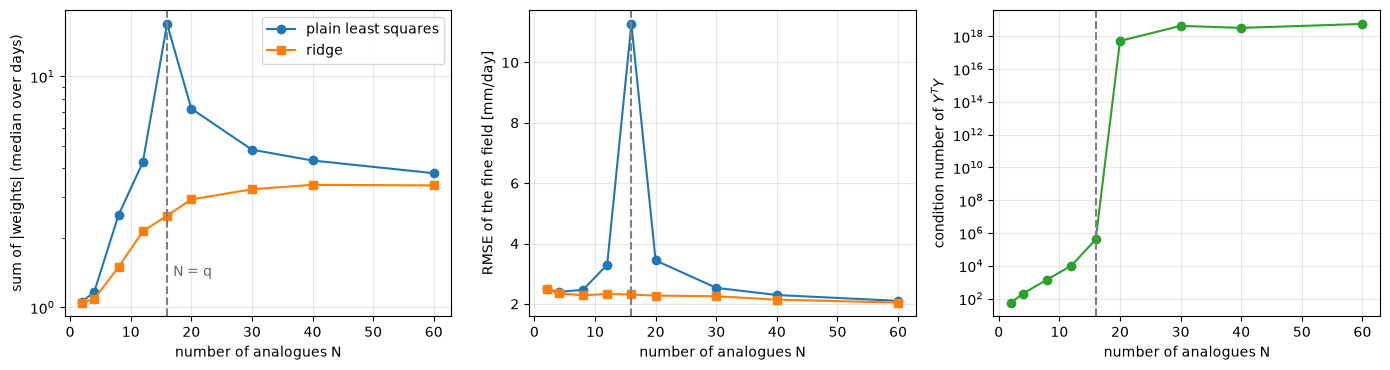

In [10]:
Y_lib, X_lib = obs_c_tr.reshape(-1, NC * NC), fine_tr.reshape(-1, NF * NF)       # training library: 240 days

def analogue_weights(Yc, y, rho):
    """Least squares (rho = 0, minimum-norm if rank deficient) or ridge with lambda = rho * mean diag(Y'Y)."""
    if rho == 0:
        return np.linalg.lstsq(Yc, y, rcond=None)[0]
    G = Yc.T @ Yc
    return np.linalg.solve(G + rho * np.trace(G) / G.shape[0] * np.eye(G.shape[0]), Yc.T @ y)

def constructed_analogue(y, N=10, rho=0.01):
    """BCCA step for one coarse field y (16,): returns the fine field (16 x 16) and the weights."""
    idx = np.argsort(np.sqrt(((Y_lib - y) ** 2).mean(1)))[:N]
    w = analogue_weights(Y_lib[idx].T, y, rho)
    return np.maximum(X_lib[idx].T @ w, 0).reshape(NF, NF), w

Ns = [2, 4, 8, 12, 16, 20, 30, 40, 60]
days = range(20)
stats = {k: [] for k in ["l1_plain", "l1_ridge", "err_plain", "err_ridge", "rank", "cond"]}
for N in Ns:
    a = {k: [] for k in stats}
    for d in days:
        y = bc_te[d].ravel()
        idx = np.argsort(np.sqrt(((Y_lib - y) ** 2).mean(1)))[:N]
        Yc = Y_lib[idx].T
        for rho, tag in ((0, "plain"), (0.01, "ridge")):
            w = analogue_weights(Yc, y, rho)
            a["l1_" + tag].append(np.abs(w).sum())
            a["err_" + tag].append(np.sqrt(((np.maximum(X_lib[idx].T @ w, 0).reshape(NF, NF) - fine_te[d]) ** 2).mean()))
        a["rank"].append(np.linalg.matrix_rank(Yc.T @ Yc)); a["cond"].append(np.linalg.cond(Yc.T @ Yc))
    for k in stats:
        stats[k].append(np.median(a[k]) if k in ("l1_plain", "l1_ridge", "cond") else np.mean(a[k]))
stats["rank"] = [int(round(r)) for r in stats["rank"]]

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].semilogy(Ns, stats["l1_plain"], "o-", label="plain least squares"); axes[0].semilogy(Ns, stats["l1_ridge"], "s-", label="ridge")
axes[0].set_ylabel("sum of |weights| (median over days)")
axes[1].plot(Ns, stats["err_plain"], "o-", label="plain least squares"); axes[1].plot(Ns, stats["err_ridge"], "s-", label="ridge")
axes[1].set_ylabel("RMSE of the fine field [mm/day]")
axes[2].semilogy(Ns, stats["cond"], "o-", color="tab:green"); axes[2].set_ylabel("condition number of $Y^T Y$")
for ax in axes:
    ax.axvline(NC * NC, color="0.5", ls="--"); ax.set_xlabel("number of analogues N"); ax.grid(alpha=0.3)
axes[0].legend(); axes[0].text(NC * NC + 1, axes[0].get_ylim()[0] * 1.5, "N = q", color="0.4")
fig.tight_layout()
print("rank of Y'Y (it is N x N) for N =", Ns, ":", stats["rank"])
x_bcca = np.array([constructed_analogue(y.ravel(), N=10, rho=0.01)[0] for y in bc_te])      # BCCA on the held-out period (N = 10)

The dashed line marks $N = q = 16$. The **condition number** of $Y^{\!\top}Y$ grows steadily with $N$ and beyond $N=q$ the rank of $Y^{\!\top}Y$ falls below $N$ (the condition number then reflects only rounding error): the normal equations have no unique solution. Around $N\approx q$ the plain weights become large and mixed in sign and the error of the fine field rises; the ridge solution keeps the weights bounded and the error low for every $N$. (Beyond $N=q$ the minimum-norm `lstsq` solution is still a valid fit, but it matches the coarse field exactly and so fits noise, which is another form of the same problem.) The practical rules: use the ridge, keep $N$ well below $q$ on small grids, and check the weights.

The code cell also applied BCCA with $N=10$ and a small ridge to the whole held-out period (scores in Section 6).

# 5) BCSA: bias correction and stochastic analogue

Constructed analogues are **deterministic** and a weighted average of several real days. Averaging smooths: if the analogues' wet spots lie in different places, the blend has weaker peaks and more even rain (Section 6 measures this). For quantities that depend on extremes or on the spatial *variability*, a flood peak or the number of cells that are wet at once, a method that reproduces realistic variability is better. **Stochastic analogue** methods produce a field that is *one realistic draw* instead of an average. Two versions are worth knowing.

**(a) BCSA as in Lee and Singh (Hwang and Graham, 2013).** Uses a fitted spatial correlation structure.

1. Transform every fine cell of the observations to a standard normal score, $z_j = \Phi^{-1}(F_j(x_j))$ ($F_j$ the cell's distribution; here the empirical one), and do the same to the bias-corrected coarse field, $z_i = \Phi^{-1}(F_{\text{obs},i}(\tilde y_i))$. This is quantile mapping to the normal distribution (Lecture 18).
2. Compute the $p\times p$ **correlation matrix** $\rho$ of the fine normal scores: it holds how rainfall at one fine cell goes with the others.
3. Generate $N_{\text{rep}}$ **replicates** $\mathbf z \sim \mathrm{MVN}(\mathbf 0, \rho)$. With the Cholesky factor $\rho = LL^{\!\top}$ and independent standard normals $\boldsymbol\varepsilon$, $\mathbf z = L\boldsymbol\varepsilon$ has exactly covariance $LL^{\!\top}=\rho$.
4. **Select** the replicate that best matches today's coarse information. The method of the book picks the one whose domain-mean score is closest to the mean of the coarse scores; a stricter variant compares all coarse cells.
5. **Back-transform** the chosen replicate cell by cell, $\hat x_j = F_j^{-1}(\Phi(z_j))$.

By construction every replicate has the right distribution at each cell and the observed spatial correlation, so variability is realistic. How *closely* it follows today's actual pattern depends only on the selection step: with the domain mean alone, little.

**(b) Analogue resampling.** Take the $K$ nearest days by the RMSE of Section 4, but instead of blending them **choose one at random**, with probabilities that decrease with rank (for example $p_k \propto 1/k$, the kernel used in the $k$-nearest-neighbour resampling of Lecture 22), and use its *fine field* (rescaled so that its mean matches today's coarse mean). Everything in the field is a real, physically coherent day; the randomness reproduces the spread of fine-scale patterns that go with a given coarse field.

Both are one draw of many possible fine fields consistent with the coarse input, so for a study of impacts one would produce several and carry them all through the hydrological model.

In [11]:
# ---- (a) BCSA: normal scores, correlation matrix, replicates, selection, back-transformation
n_tr = len(fine_tr)
Xf_tr = fine_tr.reshape(n_tr, -1)
Z_tr = norm.ppf((np.argsort(np.argsort(Xf_tr, 0), 0) + 0.5) / n_tr)                  # normal scores of every fine cell
chol = np.linalg.cholesky(np.corrcoef(Z_tr.T) + 1e-6 * np.eye(NF * NF))             # rho = L L^T (tiny jitter for stability)
Xf_sorted, p_grid = np.sort(Xf_tr, 0), (np.arange(n_tr) + 0.5) / n_tr
oc_sorted = np.sort(Y_lib, 0)

def bcsa(bc_coarse, n_rep=2000, match="mean", seed=1):
    rng = np.random.default_rng(seed)
    out = []
    for y in bc_coarse.reshape(len(bc_coarse), -1):
        zc = np.array([norm.ppf(np.interp(y[i], oc_sorted[:, i], p_grid)) for i in range(NC * NC)])   # coarse normal scores
        rep = rng.standard_normal((n_rep, NF * NF)) @ chol.T                                         # replicates, corr = rho
        if match == "mean":
            crit = np.abs(rep.mean(1) - zc.mean())                                                   # domain mean only (the book)
        else:
            crit = ((block_mean(rep.reshape(n_rep, NF, NF)).reshape(n_rep, -1) - zc) ** 2).sum(1)    # all coarse cells
        z = rep[np.argmin(crit)]
        pz = norm.cdf(z)
        out.append(np.array([np.interp(pz[j], p_grid, Xf_sorted[:, j]) for j in range(NF * NF)]).reshape(NF, NF))
    return np.array(out)

# ---- (b) stochastic analogue: pick one of the K nearest days with probability ~ 1/rank
def stochastic_analogue(bc_coarse, K=10, seed=2):
    rng = np.random.default_rng(seed)
    pk = 1 / np.arange(1, K + 1); pk /= pk.sum()
    out = []
    for y in bc_coarse.reshape(len(bc_coarse), -1):
        idx = np.argsort(np.sqrt(((Y_lib - y) ** 2).mean(1)))[:K]
        h = rng.choice(idx, p=pk)
        out.append(fine_tr[h] * y.mean() / Y_lib[h].mean())          # rescale so the domain mean matches today's coarse mean
    return np.array(out)

x_bcsa = bcsa(bc_te)
x_sa = stochastic_analogue(bc_te)
print("BCSA replicate for the wet day: min %.2f, max %.1f mm/day;  stochastic analogue: max %.1f mm/day;  truth max %.1f"
      % (x_bcsa[ridge_day].min(), x_bcsa[ridge_day].max(), x_sa[ridge_day].max(), fine_te[ridge_day].max()))

BCSA replicate for the wet day: min 2.10, max 136.4 mm/day;  stochastic analogue: max 105.4 mm/day;  truth max 102.9


# 6) Comparing the methods

| | **Interpolation** (after bias correction) | **BCSD** | **BCCA** | **BCSA** (a: replicates, b: resampling) |
|:--|:--|:--|:--|:--|
| **Idea** | Smooth blend of neighbouring coarse values | Interpolated *factor* times fine observed climatology | Combination of the $N$ most similar past coarse fields; same weights on their fine fields | One random fine field consistent with the coarse input |
| **What it preserves** | The coarse field (nearly); smoothness | Fine-scale climatology (terrain); mean approximately | Real day-to-day spatial patterns; the coarse field (well) | Variance and extremes at each cell; the observed spatial correlation |
| **What it smooths or loses** | Everything inside a coarse cell; extremes | Day-to-day change of the fine pattern; within-cell variability *of the day*; fine extremes are only those of the coarse field times the climatological pattern | Variance and peaks (averaging); weights can be unstable | Skill for the particular day: the result is one of many equally likely fields, so it matches the true pattern less closely |
| **Cost** | Trivial | Low (one quantile map, one interpolation) | Moderate (ranking and a small regularised solve per day) | Moderate to high (many replicates, large correlation matrix) |
| **Main assumptions** | The coarse field has the right shape inside cells | The *climatological* fine pattern is stationary; anomalies are smooth | The library contains days like the target (also in a warmer climate); linearity of the combination | The fine-scale correlation and marginal distributions are stationary; the coarse field is informative enough |
| **Needs** | Coarse field only | Fine *climatology*, coarse obs, GCM | A long, daily fine-resolution *library* | A long fine-resolution library (for correlations and distributions) |

*Validation.* Because we know the truth, we can score all methods on the 60 held-out days. The metrics, each computed against the true fine fields:

- **Pattern correlation** $r_{\text{day}}$: spatial correlation between the downscaled and true field of each day, averaged over days. $r_{\text{clim}}$: the same for the *time-mean* map (is the terrain pattern preserved?).
- **Bias**, $100\,(\overline{\hat x} - \overline{x})/\overline{x}$, in per cent, and **RMSE** in mm/day.
- **Variance ratio**: for each fine cell the ratio of the variance over days of the downscaled to the true series; the table gives the median over cells (1 is ideal; below 1 means the method is too smooth in time).
- **Within-block detail**: the average spatial standard deviation of the 16 fine cells inside a coarse cell, as a ratio to the truth (how much of the sub-grid pattern survives).
- **P95 ratio**: the 95th percentile over days of the downscaled field divided by the true one, averaged over cells (extremes).

In [12]:
def within_block_std(a):
    return a.reshape(-1, NC, F, NC, F).transpose(0, 1, 3, 2, 4).reshape(-1, NC, NC, F * F).std(-1).mean()

def metrics(est, truth):
    return {
        "r_day": np.mean([np.corrcoef(e.ravel(), t.ravel())[0, 1] for e, t in zip(est, truth)]),
        "r_clim": np.corrcoef(est.mean(0).ravel(), truth.mean(0).ravel())[0, 1],
        "bias %": 100 * (est.mean() - truth.mean()) / truth.mean(),
        "RMSE": np.sqrt(((est - truth) ** 2).mean()),
        "var ratio": np.median(est.var(0) / truth.var(0)),
        "within-block": within_block_std(est) / within_block_std(truth),
        "P95 ratio": np.mean(np.percentile(est, 95, axis=0) / np.percentile(truth, 95, axis=0)),
    }

results = {
    "raw GCM, bilinear":             bilinear_grid(gcm_te),
    "bias-corrected, bilinear":      bilinear_grid(bc_te),
    "BCSD":                          x_bcsd,
    "BCCA (N=10, ridge)":            x_bcca,
    "BCSA (a) replicates":           x_bcsa,
    "stochastic analogue (b)":       x_sa,
}
table = pd.DataFrame({k: metrics(v, fine_te) for k, v in results.items()}).T
print(table.round(2).to_string())

                          r_day  r_clim  bias %  RMSE  var ratio  within-block  P95 ratio
raw GCM, bilinear          0.72    0.79   54.57  6.64       2.46          0.69       1.79
bias-corrected, bilinear   0.76    0.83   -0.77  4.45       0.96          0.37       1.10
BCSD                       0.88    1.00   -0.94  2.91       0.69          0.79       0.91
BCCA (N=10, ridge)         0.86    1.00   -0.17  3.11       0.66          0.88       0.91
BCSA (a) replicates        0.56    0.99    1.86  6.02       1.26          1.05       1.12
stochastic analogue (b)    0.74    0.99   -0.77  4.23       0.83          0.99       0.95


Text(0.5, 0.98, 'One held-out day: truth and downscaled fields (synthetic data)')

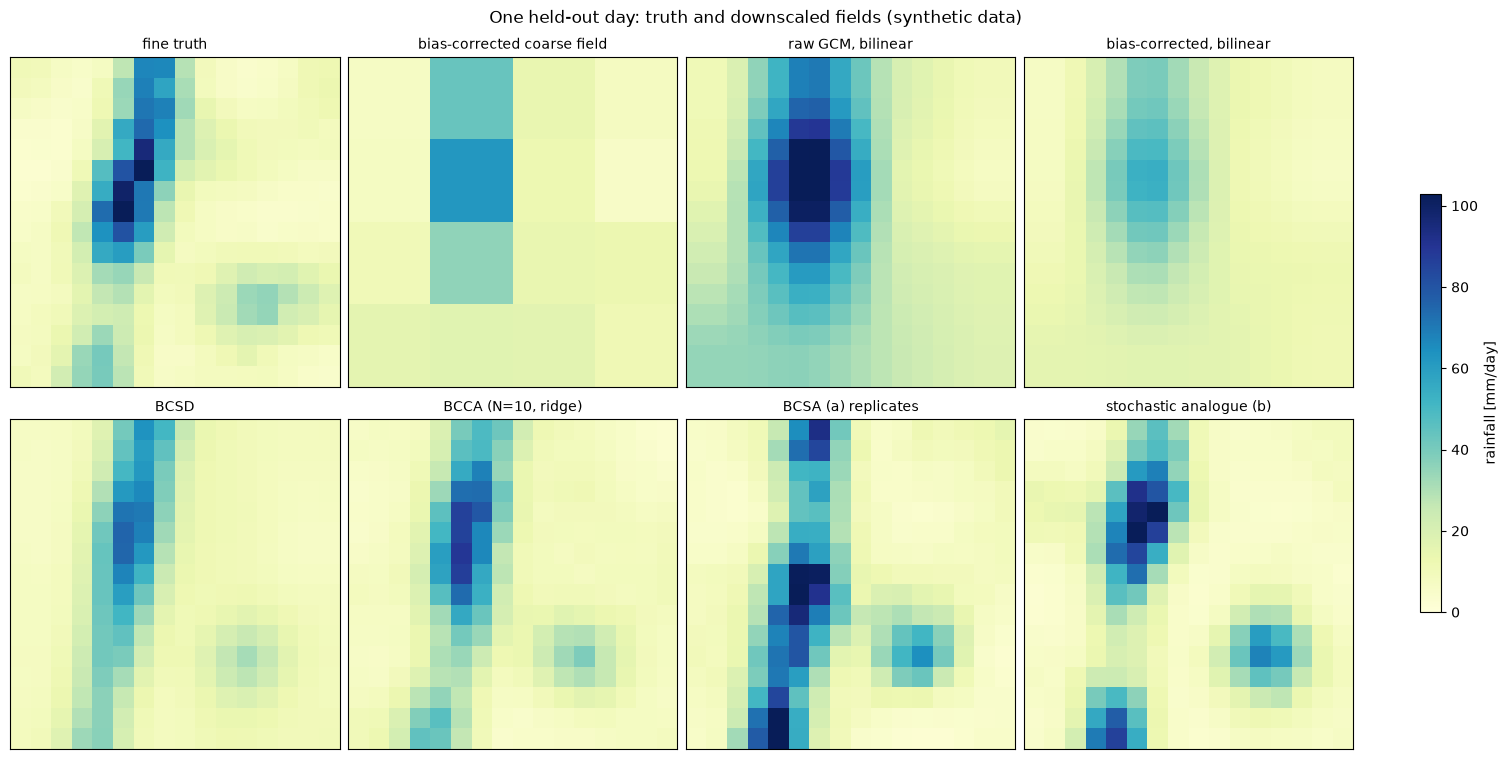

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5), constrained_layout=True)
maps = [("fine truth", fine_te[ridge_day]), ("bias-corrected coarse field", nearest_grid(bc_te[ridge_day]))] + \
       [(k, v[ridge_day]) for k, v in results.items()]
for ax, (title, fld) in zip(axes.ravel(), maps):
    im = ax.imshow(fld, origin="lower", extent=ext, cmap="YlGnBu", vmin=0, vmax=fine_te[ridge_day].max())
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.6, label="rainfall [mm/day]")
fig.suptitle("One held-out day: truth and downscaled fields (synthetic data)")

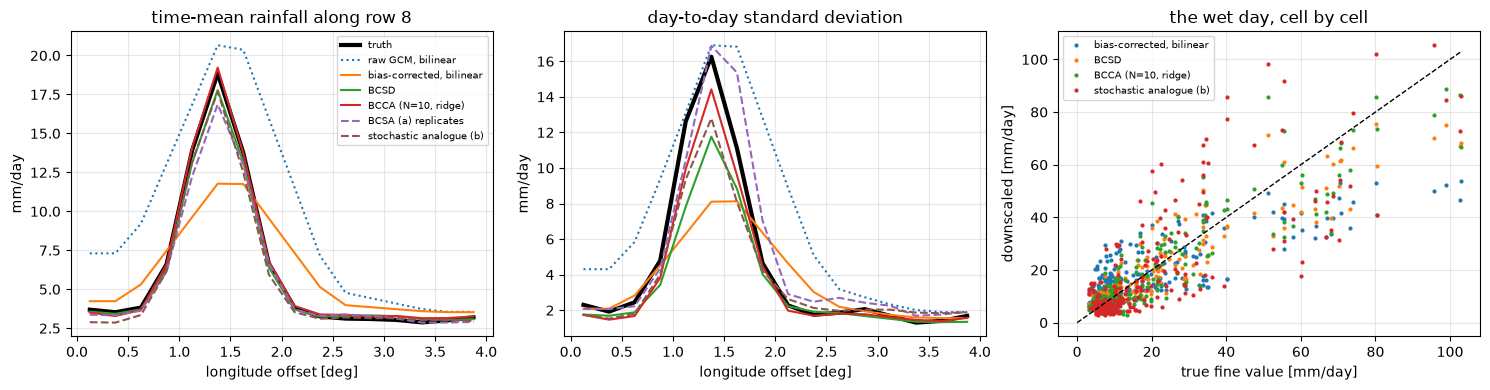

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
xs = (np.arange(NF) + 0.5) * 0.25
sty = {"raw GCM, bilinear": ":", "bias-corrected, bilinear": "-", "BCSD": "-", "BCCA (N=10, ridge)": "-",
       "BCSA (a) replicates": "--", "stochastic analogue (b)": "--"}
axes[0].plot(xs, fine_te.mean(0)[row], "k", lw=3, label="truth")
axes[1].plot(xs, fine_te.std(0)[row], "k", lw=3, label="truth")
for k, v in results.items():
    axes[0].plot(xs, v.mean(0)[row], sty[k], label=k); axes[1].plot(xs, v.std(0)[row], sty[k], label=k)
axes[0].set_title(f"time-mean rainfall along row {row}"); axes[1].set_title("day-to-day standard deviation")
for ax in axes[:2]:
    ax.set_xlabel("longitude offset [deg]"); ax.set_ylabel("mm/day"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
# scatter: fine-scale detail of the single day, estimated vs true (cell by cell)
for k in ["bias-corrected, bilinear", "BCSD", "BCCA (N=10, ridge)", "stochastic analogue (b)"]:
    axes[2].plot(fine_te[ridge_day].ravel(), results[k][ridge_day].ravel(), ".", ms=4, label=k)
m = fine_te[ridge_day].max(); axes[2].plot([0, m], [0, m], "k--", lw=1)
axes[2].set_xlabel("true fine value [mm/day]"); axes[2].set_ylabel("downscaled [mm/day]"); axes[2].set_title("the wet day, cell by cell")
axes[2].legend(fontsize=7); axes[2].grid(alpha=0.3)
fig.tight_layout()

**Reading the results** (synthetic data, one random realisation; the ranking of the stochastic methods will move a little with the random seed).

- **Raw GCM, interpolated**: the bias is large, the variance far too high, and the ridge is absent. This is what we avoid by bias-correcting.
- **Bias correction + interpolation** fixes the mean, the variance and the P95 at *coarse* scale, but keeps the pattern within cells smooth: the within-block detail ratio is well below one and the time-mean map has no ridge. The quantile mapping did its job; the spatial step is what is missing.
- **BCSD** puts the ridge in (see the time-mean cross-section) and has the highest day-to-day pattern correlation and the lowest RMSE of all. But on the ridge its day-to-day standard deviation is clearly too small (second panel): the ridge always has the climatological shape, scaled by the coarse factor, so it cannot become relatively wetter on days of strong onshore flow. The median variance ratio is also lowered by the local noise of the synthetic fields, which no method can predict from the coarse field. Its P95 ratio is below one, so BCSD is conservative for extremes.
- **BCCA** also reproduces the ridge, because the analogues are real days. It keeps more sub-grid detail than BCSD (within-block ratio higher) and more variance on the ridge (second panel), as the analogues carry days with a stronger ridge pattern, at a small cost in day-to-day correlation and RMSE.
- **The stochastic methods** restore the within-block variability to about the true level, but their pattern correlation with the *actual* day and their RMSE are worse: a random draw is not a prediction. The book's BCSA, which matches only the domain mean, has the lowest skill, and its variance ratio overshoots one; resampling a nearby analogue day is better because it uses the whole coarse pattern. (Cell by cell, in the right-hand panel, the stochastic analogue scatters most around the 1:1 line, the deterministic methods are systematically below it at high values.)

No method is best on every measure: **BCSD wins on accuracy of the mean state and of the day, the stochastic methods on variability, BCCA in between.** Choose by the question: a long-term water balance of a catchment needs the climatology (BCSD); a flood study that needs peaks and the number of wet cells needs realistic variability (stochastic, several members).

**A caution about the test itself.** In this synthetic experiment the model's "day $t$" corresponds to the observed day $t$ (the GCM is the coarse truth plus distortion and noise), so day-by-day scores such as $r_{\text{day}}$ and RMSE make sense. A real free-running GCM has **no day-to-day correspondence** with the observed weather; for it the correct validation compares *distributions and statistics*: the climatology map, the variance, the spatial correlation between cells, the frequency of heavy-rain days, using a held-out period and, better still, a *reanalysis* as a pseudo-GCM, for which the day-by-day correspondence holds. The same holds for all methods, and in a changed climate they additionally assume that the fine-scale patterns and the relation between coarse and fine fields stay as they were (stationarity), which a held-out *historical* test cannot prove; testing on a warm period against a cool one is a stronger check.

# 7) Summary

- Spatial downscaling turns a coarse field $\mathbf y$ ($q$ cells) into a fine field $\mathbf x$ ($p \gg q$ cells); it must supply the fine-scale *climatology* (terrain) and, if possible, the fine-scale *weather*.
- **Bilinear interpolation** is linear in $x$ and then in $y$: $z = \sum w\,z_k$ with $w_{00} = (1-t_x)(1-t_y)$ etc., the weights are opposite-rectangle areas, they are non-negative and sum to one. Hence it smooths, creates no new extremes and adds no information. Alone it fails: no ridge, no extremes, the model's bias remains.
- **BCSD**: quantile-map the coarse GCM to the coarse observations; form $R_i = \tilde y_i/\bar y_{\text{obs},i}$ (rainfall) or $A_i = \tilde y_i-\bar y_{\text{obs},i}$ (temperature); interpolate the factor; multiply (or add) the fine observed climatology. It is cheap and accurate on average but gives every day the climatological pattern and smooths day-to-day variability.
- **BCCA**: choose the $N$ days with the most similar coarse field, solve $\min\lVert\mathbf y - Y\mathbf w\rVert^2$, apply $\mathbf w$ to their fine fields. Unregularised, $Y^{\!\top}Y$ is (nearly) singular and the weights blow up; the **ridge** solution $(Y^{\!\top}Y+\lambda I)^{-1}Y^{\!\top}\mathbf y$ and a small $N$ cure it. Real patterns, but averaging reduces variance.
- **BCSA**: a stochastic draw (correlated normal replicates, or a randomly chosen analogue day) keeps realistic variability and extremes at the cost of skill for the individual day.
- Validate on a **held-out period** with pattern correlation, bias, variance ratio and a check of preserved spatial detail; with a real GCM compare statistics, not days.

# 8) Check your understanding

1. A fine point lies exactly at the centre of a coarse cell's four surrounding nodes ($t_x=t_y=0.5$). What are the four weights, and what is the value if the nodes are 4, 8, 12 and 20 mm/day? Could the result ever be 22 mm/day, and why not?
2. Why can bilinear interpolation of a *perfect* coarse field not recover a 15 mm/day ridge that is one fine cell wide? Which information would have to be added, and where does BCSD get it from?
3. A mountain valley point has a winter climatology of $-3$ &deg;C and the coarse model, bias corrected, is $+2$ &deg;C above its coarse climatology of $5$ &deg;C. Compute the BCSD result with the additive and the multiplicative rules. Which is physically sensible?
4. In BCCA you have a coarse grid of 16 cells and use $N=40$ analogues. What is the largest possible rank of $Y^{\!\top}Y$? What happens to the least-squares weights, and what does a ridge term do?
5. A flood study needs the 95th percentile of daily rainfall at a catchment cell. Which of the four spatial methods of this lecture would you not rely on, and why? What would you do about it?

# 9) Try it yourself

- Change $N$ in `constructed_analogue` (try 3, 5, 10, 20) and the ridge parameter `rho` (0, 0.001, 0.01, 0.1), and watch the row of `BCCA` in the metrics table. Is there a best $\lambda$?
- In `make_lec23_data.py` (same folder as the CSV files) change the strength of the day-to-day orographic enhancement and regenerate the data. Do BCCA and the stochastic analogue gain on BCSD when the ridge pattern varies more?
- Rerun `bcsa` with `match="coarse"` (all coarse cells in the selection): how much of the lost skill returns?
- Apply the *additive* BCSD (`mode="additive"`) to the rainfall and count the negative values. Then try it on a synthetic temperature field.
- Open the workbook, set $\lambda = 0$ on the sheet `Data` and compare the plain and ridge weights; then change the target coarse field and see which days become the analogues.
- *Optional:* replace the synthetic arrays by real ones: IMD gridded rainfall at 0.25&deg; for a $4^\circ\times4^\circ$ window (Lecture 15) as the fine observations, its $1^\circ$ block averages as the coarse observations, and a coarse CMIP6 field for the model.

```{note} Sources
**Reference for the methods.** Lee, T., & Singh, V. P. (2019). *Statistical Downscaling for Hydrological and Environmental Applications*. CRC Press, Chapter 9 (bilinear and nearest-neighbour interpolation, BCSD, BCCA, BCSA, and the comparison of the three). The equations here were derived afresh for this course, the data are our own, and the figures are drawn for this course. Two points differ from the book's presentation: the book's BCCA regression includes an intercept and no regularisation, while the notebook omits the intercept and adds the ridge term (the regularised inverse is standard practice in the constructed-analogue literature); and the book's BCSA selects the replicate by the domain mean only, which is why the notebook also shows the stricter and the analogue-resampling variants.

**Original method papers.** Wood, A. W., Leung, L. R., Sridhar, V., & Lettenmaier, D. P. (2004). Hydrologic implications of dynamical and statistical approaches to downscaling climate model outputs. *Climatic Change, 62*, 189&ndash;216 (BCSD). &middot; Hidalgo, H. G., Dettinger, M. D., & Cayan, D. R. (2008). *Downscaling with constructed analogues: Daily precipitation and temperature fields over the United States*. California Energy Commission PIER report (constructed analogues). &middot; Maurer, E. P., Hidalgo, H. G., Das, T., Dettinger, M. D., & Cayan, D. R. (2010). The utility of daily large-scale climate data in the assessment of climate change impacts on daily streamflow in California. *Hydrol. Earth Syst. Sci., 14*, 1125&ndash;1138 (BCCA). &middot; Hwang, S., & Graham, W. D. (2013). Development and comparative evaluation of a stochastic analog method to downscale daily GCM precipitation. *Hydrol. Earth Syst. Sci., 17* (BCSA).

**Data.** All arrays are synthetic (`data/downscaling/lec23/`, generated by `make_lec23_data.py` with a fixed seed; the companion workbook is built by `build_lec23_xlsx.py`). To use real data, take IMD gridded rainfall (0.25&deg;) as the fine observations and a CMIP6 or NEX-GDDP-CMIP6 field as the coarse model.

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```